In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

retail_sales = pd.read_csv(
    "../datasets/ts-course-data/us-retail-sales.csv",
    parse_dates=['Month'],
    index_col='Month'
).to_period('D')
food_sales = retail_sales.loc[:, 'FoodAndBeverage']
auto_sales = retail_sales.loc[:, 'Automobiles']

dtype = {
    'store_nbr': 'category',
    'family': 'category',
    'sales': 'float32',
    'onpromotion': 'uint64',
}
store_sales = pd.read_csv(
    '../datasets/store-sales-time-series-forecasting/train.csv',
    dtype=dtype,
    parse_dates=['date']
)
store_sales = store_sales.set_index('date').to_period('D')
store_sales = store_sales.set_index(['store_nbr', 'family'], append=True)
average_sales = store_sales.groupby('date').mean()['sales']

[Text(0.5, 1.0, 'US Food and Beverage Sales'),
 Text(0, 0.5, 'Millions of Dollars')]

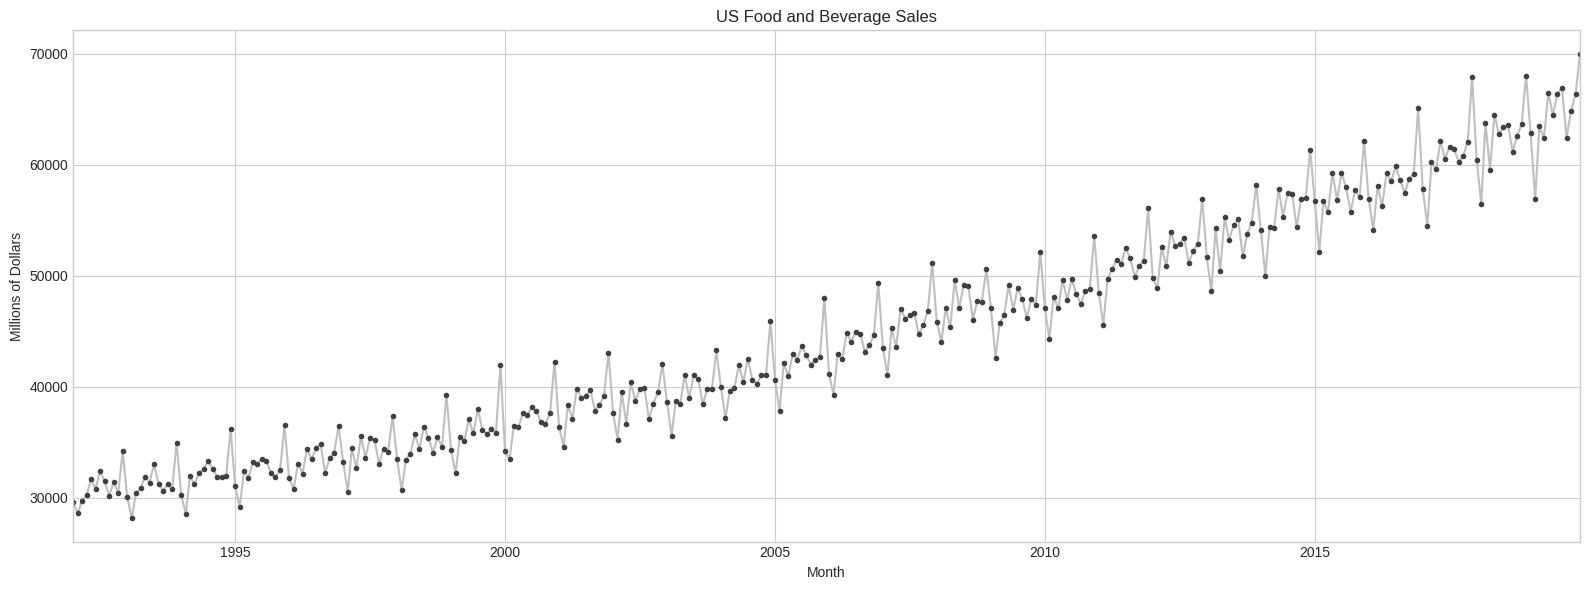

In [2]:
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(16, 6))

plot_params = {
    'color': '0.75',
    'style': '.-',
    'markeredgecolor': '0.25',
    'markerfacecolor': '0.25',
    'legend': False
}

ax = food_sales.plot(**plot_params)
ax.set(title="US Food and Beverage Sales", ylabel="Millions of Dollars")

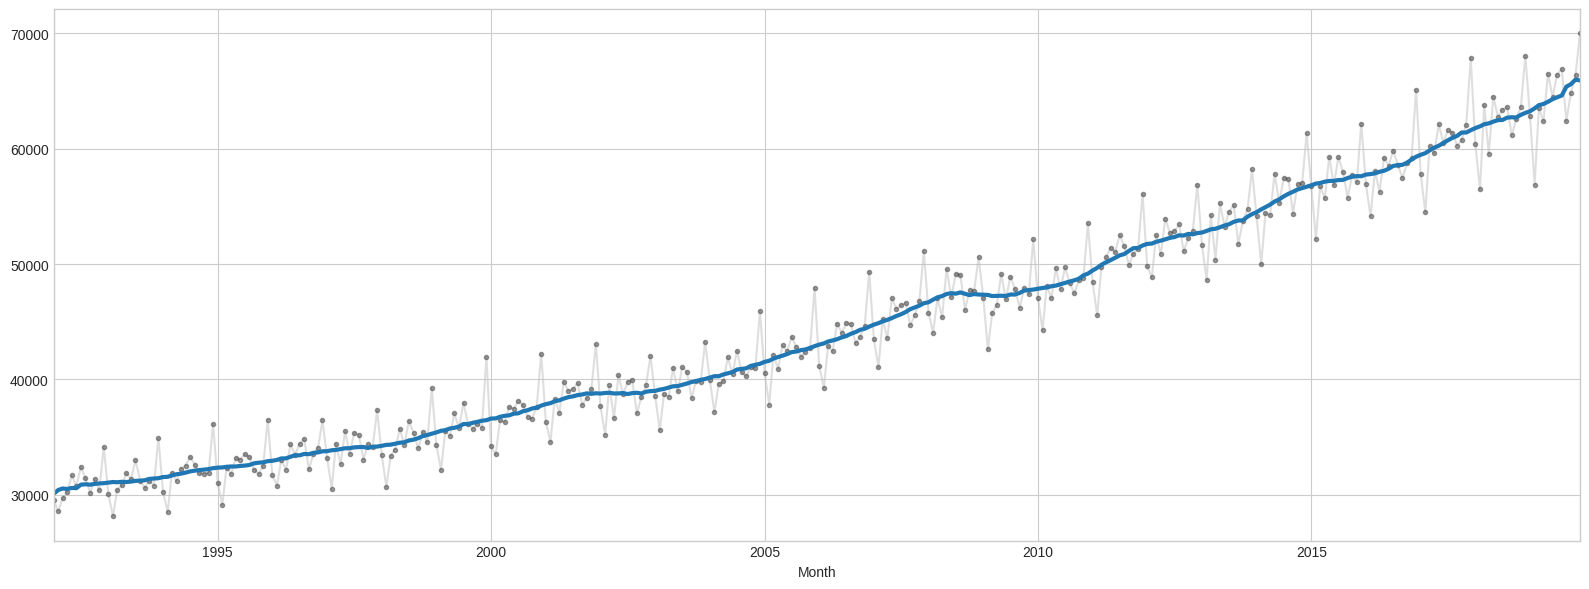

In [3]:
# Add methods to `food_sales` to compute a moving
# average with appropriate parameters for trend estimation.
trend = food_sales.rolling(
    window=12,       # 12-day window
    center=True,
    min_periods=6,
).mean()

ax = food_sales.plot(**plot_params, alpha=0.5)
ax = trend.plot(ax=ax, linewidth=3)

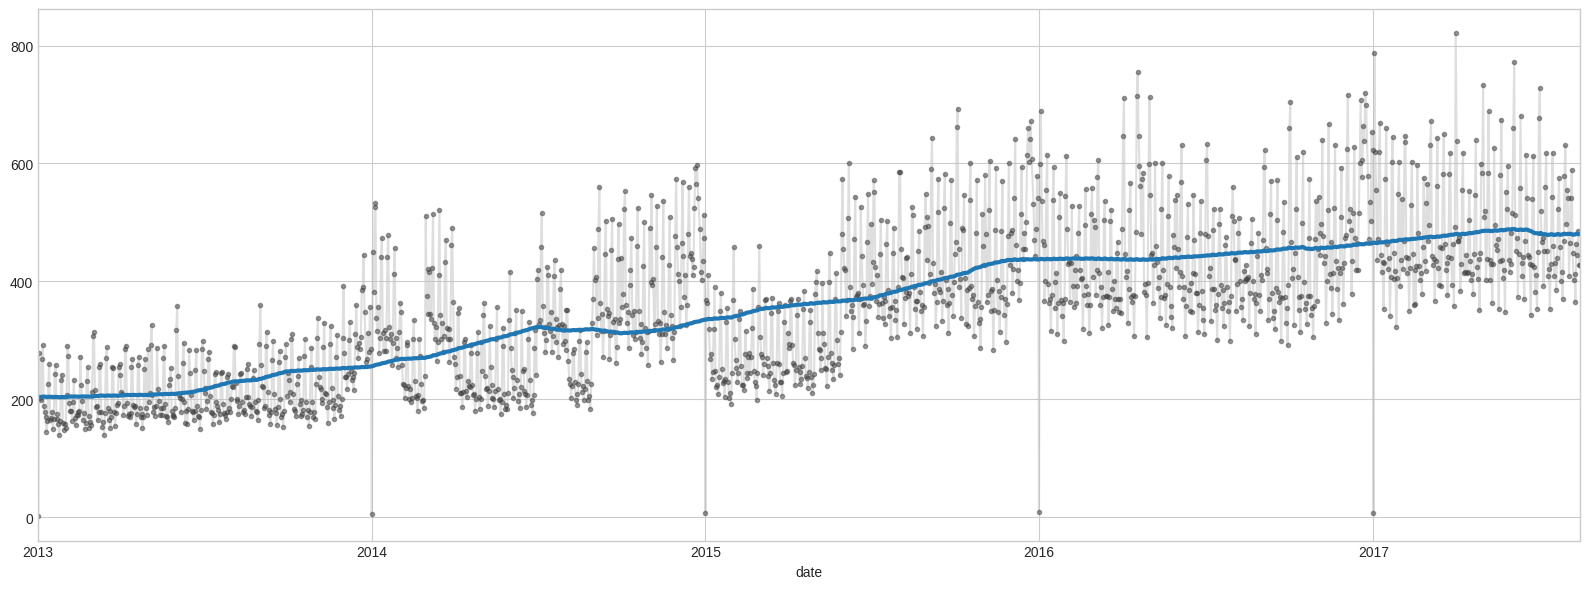

In [4]:
trend = average_sales.rolling(
    window=365,
    center=True,
    min_periods=183,
).mean()

ax = average_sales.plot(**plot_params, alpha=0.5)
ax = trend.plot(ax=ax, linewidth=3)

In [5]:
from statsmodels.tsa.deterministic import DeterministicProcess

y = average_sales.copy()  # the target

# Instantiate `DeterministicProcess` with arguments appropriate for a cubic trend model
dp = DeterministicProcess(
    y.index,
    order=3,
)

# Create the feature set for the dates given in y.index
X = dp.in_sample()

# Create features for a 90-day forecast.
X_fore = dp.out_of_sample(steps=90)

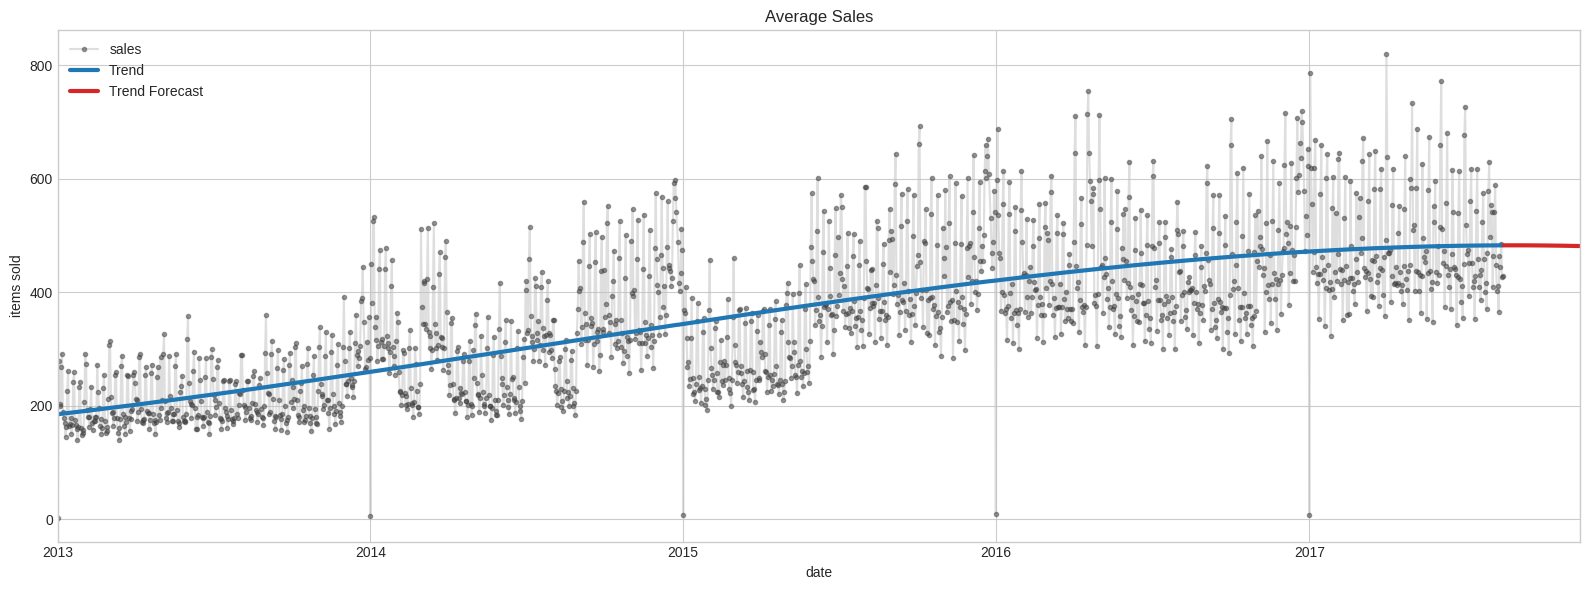

In [6]:
model = LinearRegression()
model.fit(X, y)

y_pred = pd.Series(model.predict(X), index=X.index)
y_fore = pd.Series(model.predict(X_fore), index=X_fore.index)

ax = y.plot(**plot_params, alpha=0.5, title="Average Sales", ylabel="items sold")
ax = y_pred.plot(ax=ax, linewidth=3, label="Trend", color='C0')
ax = y_fore.plot(ax=ax, linewidth=3, label="Trend Forecast", color='C3')
ax.legend();

In [9]:
from IPython.display import display, Markdown

content = f"""
One way to fit more complicated trends is to increase the order of the polynomial you use. 
To get a better fit to the somewhat complicated trend in Store Sales, we could try using an order 11 
polynomial.
"""

display(Markdown(content))


One way to fit more complicated trends is to increase the order of the polynomial you use. 
To get a better fit to the somewhat complicated trend in Store Sales, we could try using an order 11 
polynomial.


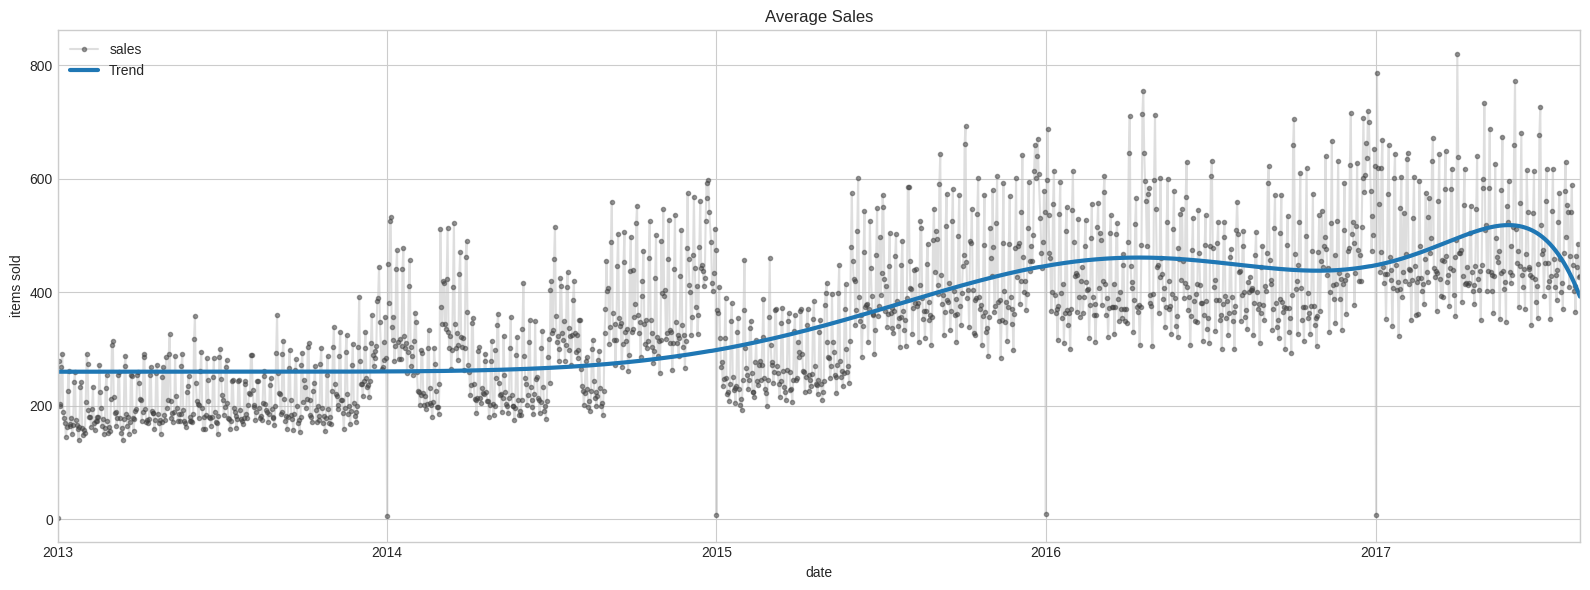

In [7]:
from statsmodels.tsa.deterministic import DeterministicProcess

dp = DeterministicProcess(index=y.index, order=11)
X = dp.in_sample()

model = LinearRegression()
model.fit(X, y)

y_pred = pd.Series(model.predict(X), index=X.index)

ax = y.plot(**plot_params, alpha=0.5, title="Average Sales", ylabel="items sold")
ax = y_pred.plot(ax=ax, linewidth=3, label="Trend", color='C0')
ax.legend();

In [10]:
content = f"""
High-order polynomials are generally not well-suited to forecasting, however. 
An order 11 polynomial will include terms like t ** 11. Terms like these tend to diverge 
rapidly outside of the training period making forecasts very unreliable.
"""

display(Markdown(content))


High-order polynomials are generally not well-suited to forecasting, however. 
An order 11 polynomial will include terms like t ** 11. Terms like these tend to diverge 
rapidly outside of the training period making forecasts very unreliable.


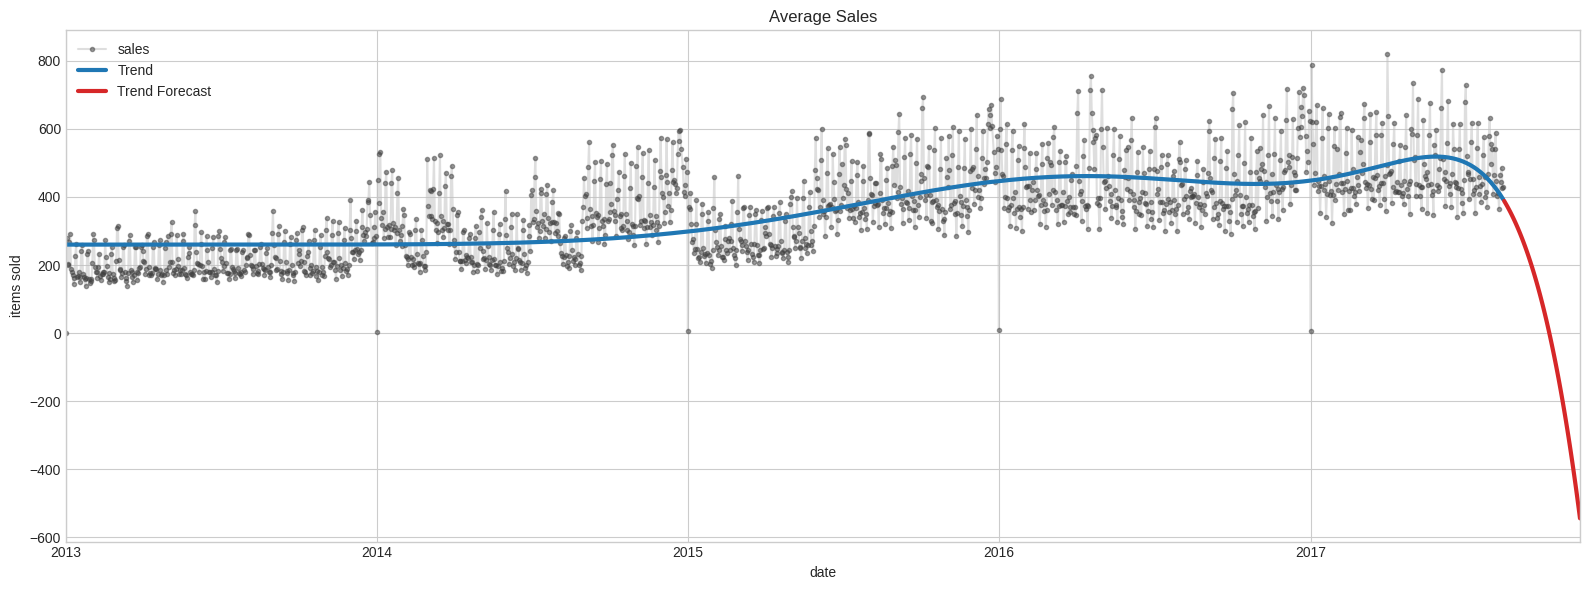

In [11]:
X_fore = dp.out_of_sample(steps=90)
y_fore = pd.Series(model.predict(X_fore), index=X_fore.index)

ax = y.plot(**plot_params, alpha=0.5, title="Average Sales", ylabel="items sold")
ax = y_pred.plot(ax=ax, linewidth=3, label="Trend", color='C0')
ax = y_fore.plot(ax=ax, linewidth=3, label="Trend Forecast", color='C3')
ax.legend();